In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [ ]:
SEED = 42
MAX_EPOCHS = 10
BATCH_SIZE = 128
LEARNING_RATE = 0.001
ORIGINAL_DIM = 784
HIDDEN_DIM = 256
LATENT_DIM = 64

In [ ]:
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
original_train = datasets.FashionMNIST(
    root="./data", train=True, download=True,
    transform=transforms.ToTensor()
)
original_test = datasets.FashionMNIST(
    root="./data", train=False, download=True,
    transform=transforms.ToTensor()
)


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.72MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.6MB/s]


In [ ]:
dataset = ConcatDataset([original_train, original_test])

train_data, val_data, test_data = random_split(
    dataset, [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))


Train: 56000
Validation: 7000
Test: 7000


In [ ]:
train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)


In [ ]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(ORIGINAL_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, ORIGINAL_DIM),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.flatten(1)
        z = self.encoder(x)
        return self.decoder(z)


In [ ]:
import time

def sync_gpu():
    if device.type == "cuda":
        torch.cuda.synchronize()

torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)

ae = Autoencoder().to(device)
ae_optimizer = optim.Adam(ae.parameters(), lr=LEARNING_RATE)
ae_loss = nn.MSELoss()

ae_train_loss = []
ae_val_loss = []
ae_epoch_time = []

for epoch in range(MAX_EPOCHS):
    # Training
    ae.train()
    total_loss = 0

    sync_gpu()
    start = time.perf_counter()

    for images, _ in train_loader:
        images = images.to(device)

        ae_optimizer.zero_grad()
        outputs = ae(images)
        loss = ae_loss(outputs, images.flatten(1))
        loss.backward()
        ae_optimizer.step()

        total_loss += loss.item() * images.size(0)

    sync_gpu()
    ae_epoch_time.append(time.perf_counter() - start)
    ae_train_loss.append(total_loss / len(train_data))

    # Validation
    ae.eval()
    total_val = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            outputs = ae(images)
            loss = ae_loss(outputs, images.flatten(1))

            total_val += loss.item() * images.size(0)

    ae_val_loss.append(total_val / len(val_data))

    print(
        f"Epoch {epoch+1}: "
        f"train={ae_train_loss[-1]:.5f}, "
        f"val={ae_val_loss[-1]:.5f}"
    )

Epoch 1: train=0.03465, val=0.01980
Epoch 2: train=0.01767, val=0.01639
Epoch 3: train=0.01513, val=0.01448
Epoch 4: train=0.01358, val=0.01335
Epoch 5: train=0.01257, val=0.01247
Epoch 6: train=0.01188, val=0.01180
Epoch 7: train=0.01133, val=0.01154
Epoch 8: train=0.01085, val=0.01093
Epoch 9: train=0.01046, val=0.01060
Epoch 10: train=0.01013, val=0.01030


In [ ]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(ORIGINAL_DIM, HIDDEN_DIM)
        self.mean = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.log_var = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, ORIGINAL_DIM)
        )

    def encode(self, x):
        h = torch.relu(self.hidden(x.flatten(1)))
        return self.mean(h), self.log_var(h)

    def reparameterize(self, mean, log_var):
        std = torch.exp(0.5 * log_var)
        noise = torch.randn_like(std)
        return mean + std * noise

    def decode(self, z):
        return torch.sigmoid(self.decoder(z))

    def forward(self, x):
        mean, log_var = self.encode(x)
        z = self.reparameterize(mean, log_var)
        return self.decoder(z), mean, log_var


In [ ]:
bce_loss = nn.BCEWithLogitsLoss(reduction="sum")

def vae_loss(logits, images, mean, log_var):
    reconstruction = bce_loss(logits, images.flatten(1)) / images.size(0)
    kl = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp()) / images.size(0)
    return reconstruction + kl


In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)
vae = VAE().to(device)
vae_optimizer = optim.Adam(vae.parameters(), lr=LEARNING_RATE)

vae_train_loss = []
vae_val_loss = []
vae_epoch_time = []
best_val = float("inf")

for epoch in range(MAX_EPOCHS):
    vae.train()
    total_loss = 0
    sync_gpu()
    start = time.perf_counter()

    for images, _ in train_loader:
        images = images.to(device)
        vae_optimizer.zero_grad()
        logits, mean, log_var = vae(images)
        loss = vae_loss(logits, images, mean, log_var)
        loss.backward()
        vae_optimizer.step()
        total_loss += loss.item() * images.size(0)

    sync_gpu()
    vae_epoch_time.append(time.perf_counter() - start)
    vae_train_loss.append(total_loss / len(train_data))

    vae.eval()
    total_val = 0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            logits, mean, log_var = vae(images)
            loss = vae_loss(logits, images, mean, log_var)
            total_val += loss.item() * images.size(0)
    val_loss = total_val / len(val_data)
    vae_val_loss.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        vae_best_epoch = epoch + 1
        vae_best_weights = {k: v.detach().cpu().clone() for k, v in vae.state_dict().items()}

    print(f"Epoch {epoch+1}: train={vae_train_loss[-1]:.3f}, val={val_loss:.3f}")

vae.load_state_dict(vae_best_weights)
print("Checkpoint VAE: epoch", vae_best_epoch)


Epoch 1: train=299.866, val=274.291
Epoch 2: train=267.766, val=263.231
Epoch 3: train=258.627, val=255.925
Epoch 4: train=253.181, val=252.449
Epoch 5: train=250.214, val=250.074
Epoch 6: train=248.351, val=248.572
Epoch 7: train=247.096, val=247.999
Epoch 8: train=246.153, val=246.703
Epoch 9: train=245.449, val=246.443
Epoch 10: train=244.737, val=245.511
Checkpoint VAE: epoch 10


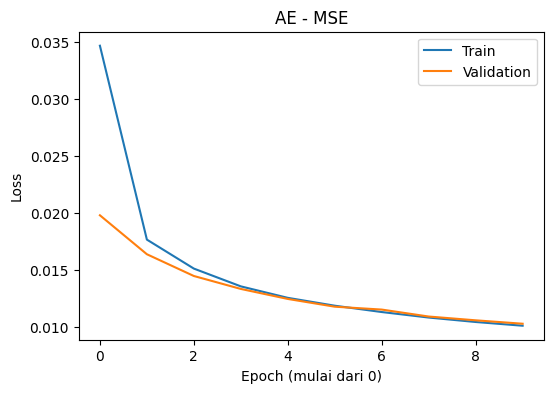

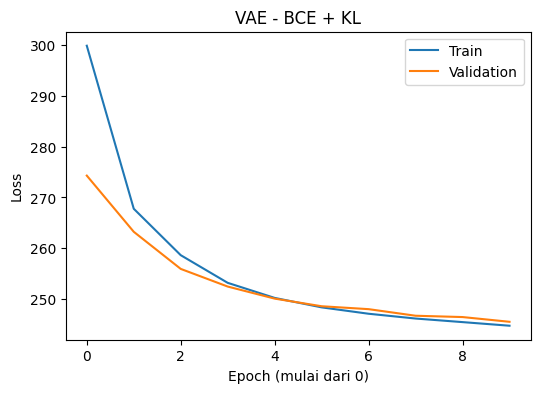

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(ae_train_loss, label="Train")
plt.plot(ae_val_loss, label="Validation")
plt.title("AE - MSE")
plt.xlabel("Epoch (mulai dari 0)")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(vae_train_loss, label="Train")
plt.plot(vae_val_loss, label="Validation")
plt.title("VAE - BCE + KL")
plt.xlabel("Epoch (mulai dari 0)")
plt.ylabel("Loss")
plt.legend()
plt.show()

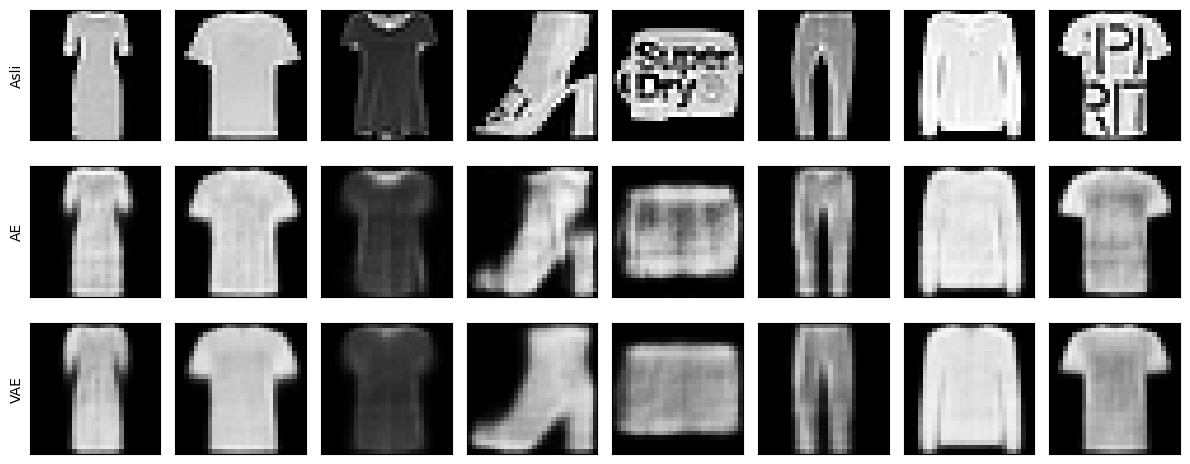

In [ ]:
ae.eval()
vae.eval()

images, labels = next(iter(test_loader))
images = images[:8].to(device)

with torch.no_grad():
    ae_images = ae(images).reshape(-1, 1, 28, 28).cpu()
    mean, _ = vae.encode(images)
    vae_images = vae.decode(mean).reshape(-1, 1, 28, 28).cpu()

rows = [images.cpu(), ae_images, vae_images]
names = ["Asli", "AE", "VAE"]

plt.figure(figsize=(12, 5))

for row in range(3):
    for col in range(8):
        plt.subplot(3, 8, row * 8 + col + 1)
        plt.imshow(rows[row][col, 0], cmap="gray", vmin=0, vmax=1)
        plt.xticks([])
        plt.yticks([])

        if col == 0:
            plt.ylabel(names[row])

plt.tight_layout()
plt.show()

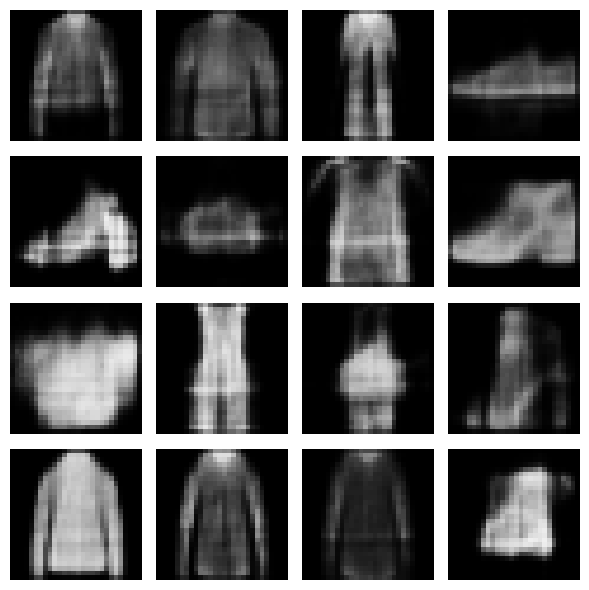

In [ ]:
torch.manual_seed(SEED)

with torch.no_grad():
    noise = torch.randn(16, LATENT_DIM, device=device)
    generated = vae.decode(noise).reshape(-1, 28, 28).cpu()

plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated[i], cmap="gray", vmin=0, vmax=1)
    plt.axis("off")

plt.tight_layout()
plt.show()

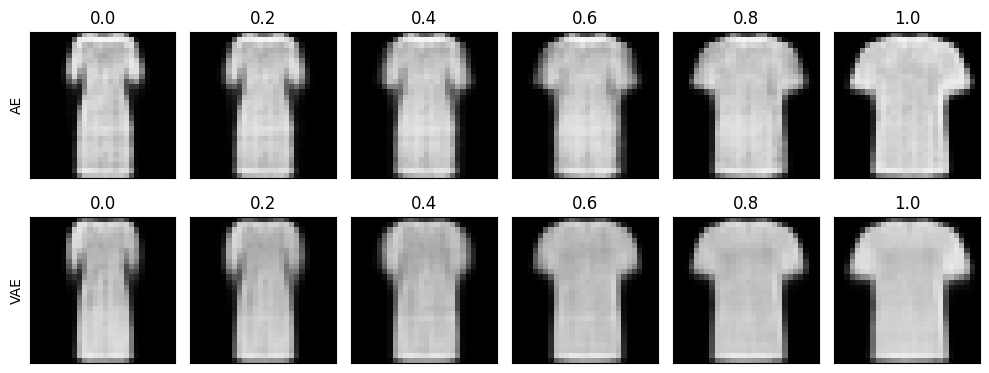

In [ ]:
image_a, label_a = test_data[0]

for image_b, label_b in test_data:
    if label_b != label_a:
        break

pair = torch.stack([image_a, image_b]).to(device)
alpha = torch.linspace(0, 1, 6, device=device).unsqueeze(1)

with torch.no_grad():
    z_ae = ae.encoder(pair.flatten(1))
    z_vae, _ = vae.encode(pair)

    ae_steps = ae.decoder(
        (1 - alpha) * z_ae[0] + alpha * z_ae[1]
    ).reshape(-1, 28, 28).cpu()

    vae_steps = vae.decode(
        (1 - alpha) * z_vae[0] + alpha * z_vae[1]
    ).reshape(-1, 28, 28).cpu()

rows = [ae_steps, vae_steps]
names = ["AE", "VAE"]

plt.figure(figsize=(10, 4))

for row in range(2):
    for col in range(6):
        plt.subplot(2, 6, row * 6 + col + 1)
        plt.imshow(rows[row][col], cmap="gray", vmin=0, vmax=1)
        plt.title(f"{col / 5:.1f}")
        plt.xticks([])
        plt.yticks([])

        if col == 0:
            plt.ylabel(names[row])

plt.tight_layout()
plt.show()

In [ ]:
from skimage.metrics import structural_similarity

def evaluate(model, is_vae=False):
    model.eval()
    mse_total = 0
    psnr_total = 0
    ssim_total = 0

    with torch.no_grad():
        for images, _ in test_loader:
            inputs = images.to(device)
            if is_vae:
                mean, _ = model.encode(inputs)
                predictions = model.decode(mean)
            else:
                predictions = model(inputs)
            predictions = predictions.reshape(-1, 1, 28, 28).cpu()

            mse = ((images - predictions)**2).flatten(1).mean(1)
            mse_total += mse.sum().item()
            psnr_total += (-10 * torch.log10(mse.clamp_min(1e-12))).sum().item()
            for original, predicted in zip(images, predictions):
                ssim_total += structural_similarity(
                    original[0].numpy(), predicted[0].numpy(),
                    data_range=1.0, win_size=7
                )

    n = len(test_data)
    return {"MSE": mse_total/n, "PSNR": psnr_total/n, "SSIM": float(ssim_total/n)}

ae_metrics = evaluate(ae)
vae_metrics = evaluate(vae, is_vae=True)
print("AE:", ae_metrics)
print("VAE:", vae_metrics)


AE: {'MSE': 0.010237696426255362, 'PSNR': 20.771824759347098, 'SSIM': 0.7528844804272818}
VAE: {'MSE': 0.014720971924918039, 'PSNR': 19.080599783761162, 'SSIM': 0.6828299985346448}


In [ ]:
def latency(operation):
    with torch.no_grad():
        for _ in range(10):
            operation()
        sync_gpu()
        start = time.perf_counter()
        for _ in range(30):
            operation()
        sync_gpu()
    return (time.perf_counter() - start) * 1000 / 30

ae.eval()
vae.eval()
batch = next(iter(test_loader))[0][:64].to(device)
noise = torch.randn(64, LATENT_DIM, device=device)
print("AE training seconds/epoch:", sum(ae_epoch_time)/len(ae_epoch_time))
print("VAE training seconds/epoch:", sum(vae_epoch_time)/len(vae_epoch_time))
print("AE reconstruction ms/batch64:", latency(lambda: ae(batch)))
print("VAE generation ms/batch64:", latency(lambda: vae.decode(noise)))

AE training seconds/epoch: 6.654056299000013
VAE training seconds/epoch: 6.863371247100008
AE reconstruction ms/batch64: 0.1713649999980286
VAE generation ms/batch64: 0.07175913333412609


In [ ]:
torch.save(ae.state_dict(), "ae_weights.pt")
torch.save(vae.state_dict(), "vae_weights.pt")

torch.save({
    "train": train_data.indices,
    "validation": val_data.indices,
    "test": test_data.indices,
    "seed": SEED
}, "split_indices.pt")

In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)

SPARSE_LAMBDA = 0.0001
sparse_ae = Autoencoder().to(device)
sparse_optimizer = optim.Adam(sparse_ae.parameters(), lr=LEARNING_RATE)
sparse_loss = nn.MSELoss()

sparse_train_loss = []
sparse_val_loss = []
sparse_epoch_time = []


In [ ]:
for epoch in range(MAX_EPOCHS):
    sparse_ae.train()
    total_loss = 0
    sync_gpu()
    start = time.perf_counter()

    for images, _ in train_loader:
        images = images.to(device)
        sparse_optimizer.zero_grad()

        z = sparse_ae.encoder(images.flatten(1))
        outputs = sparse_ae.decoder(z)
        reconstruction = sparse_loss(outputs, images.flatten(1))
        penalty = z.abs().sum(dim=1).mean()
        loss = reconstruction + SPARSE_LAMBDA * penalty

        loss.backward()
        sparse_optimizer.step()
        total_loss += reconstruction.item() * images.size(0)

    sync_gpu()
    sparse_epoch_time.append(time.perf_counter() - start)
    sparse_train_loss.append(total_loss / len(train_loader.dataset))

    sparse_ae.eval()
    total_val = 0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            loss = sparse_loss(sparse_ae(images), images.flatten(1))
            total_val += loss.item() * images.size(0)

    sparse_val_loss.append(total_val / len(val_loader.dataset))
    print(f"Epoch {epoch+1}: train MSE={sparse_train_loss[-1]:.5f}, val MSE={sparse_val_loss[-1]:.5f}")

torch.save(sparse_ae.state_dict(), "sparse_ae_weights.pt")


Epoch 1: train MSE=0.03522, val MSE=0.02032
Epoch 2: train MSE=0.01820, val MSE=0.01701
Epoch 3: train MSE=0.01588, val MSE=0.01526
Epoch 4: train MSE=0.01456, val MSE=0.01436
Epoch 5: train MSE=0.01376, val MSE=0.01381
Epoch 6: train MSE=0.01314, val MSE=0.01313
Epoch 7: train MSE=0.01265, val MSE=0.01273
Epoch 8: train MSE=0.01221, val MSE=0.01233
Epoch 9: train MSE=0.01185, val MSE=0.01208
Epoch 10: train MSE=0.01150, val MSE=0.01163


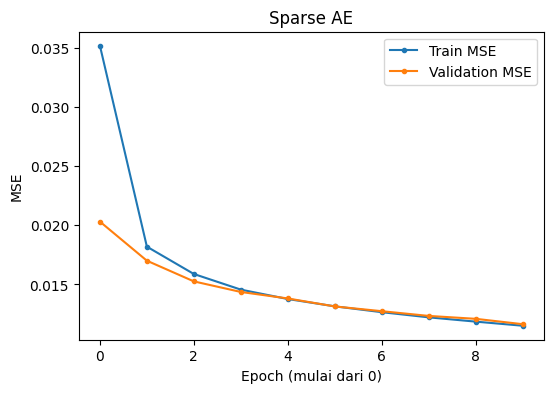

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sparse_train_loss, label="Train MSE", marker=".")
plt.plot(sparse_val_loss, label="Validation MSE", marker=".")
plt.title("Sparse AE")
plt.xlabel("Epoch (mulai dari 0)")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [ ]:
NOISE_DIM = 100

In [ ]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(noise_dim, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Tanh()
        )

    def forward(self, z):
        return self.network(z).reshape(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Dropout(0.3), nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Dropout(0.3), nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
def train_gan(generator, discriminator, g_optimizer, d_optimizer, train_loader, device, name):
    criterion = nn.BCEWithLogitsLoss()
    history = []
    for epoch in range(MAX_EPOCHS):
        generator.train()
        g_total, d_total, count = 0.0, 0.0, 0
        sync_gpu()
        start = time.perf_counter()
        for images, _ in train_loader:
            real_images = images.to(device) * 2 - 1
            n = real_images.size(0)
            discriminator.train()
            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)
            noise = torch.randn(n, NOISE_DIM, device=device)
            fake_images = generator(noise)
            d_optimizer.zero_grad()
            real_logits = discriminator(real_images)
            fake_logits = discriminator(fake_images.detach())
            d_loss = (criterion(real_logits, torch.ones_like(real_logits)) +
                      criterion(fake_logits, torch.zeros_like(fake_logits))) / 2
            d_loss.backward()
            d_optimizer.step()

            discriminator.eval()
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)
            g_optimizer.zero_grad()
            fake_logits = discriminator(fake_images)
            g_loss = criterion(fake_logits, torch.ones_like(fake_logits))
            g_loss.backward()
            g_optimizer.step()
            g_total += g_loss.item() * n
            d_total += d_loss.item() * n
            count += n
        sync_gpu()
        row = {"epoch": epoch+1, "generator_loss": g_total/count,
               "discriminator_loss": d_total/count, "seconds": time.perf_counter()-start}
        history.append(row)
        print(f"{name} {epoch+1}: G={row['generator_loss']:.3f}, D={row['discriminator_loss']:.3f}")
    for parameter in discriminator.parameters():
        parameter.requires_grad_(True)
    generator.eval()
    discriminator.eval()
    return history

In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)
gan = Generator(NOISE_DIM).to(device)
gan_discriminator = Discriminator().to(device)

g_optimizer = optim.Adam(gan.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(gan_discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
gan_history = train_gan(
    gan, gan_discriminator, g_optimizer, d_optimizer, train_loader, device, "GAN"
)

torch.save(gan.state_dict(), "gan_weights.pt")
torch.save(gan_discriminator.state_dict(), "gan_discriminator_weights.pt")

GAN 1: G=2.610, D=0.202
GAN 2: G=4.439, D=0.152
GAN 3: G=3.057, D=0.233
GAN 4: G=2.631, D=0.277
GAN 5: G=2.564, D=0.305
GAN 6: G=2.521, D=0.323
GAN 7: G=2.213, D=0.377
GAN 8: G=1.984, D=0.407
GAN 9: G=1.863, D=0.427
GAN 10: G=1.832, D=0.433


In [ ]:
class DCGenerator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False), nn.Tanh()
        )

    def forward(self, z):
        return self.network(z.reshape(z.size(0), -1, 1, 1))


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 1, 7, 1, 0, bias=False), nn.Flatten()
        )

    def forward(self, x):
        return self.network(x)


def initialize_dcgan(layer):
    if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(layer.weight, 0.0, 0.02)
    elif isinstance(layer, nn.BatchNorm2d):
        nn.init.normal_(layer.weight, 1.0, 0.02)
        nn.init.zeros_(layer.bias)

In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)
dcgan = DCGenerator(NOISE_DIM).to(device)
dcgan_discriminator = DCDiscriminator().to(device)
dcgan.apply(initialize_dcgan)
dcgan_discriminator.apply(initialize_dcgan)

g_optimizer = optim.Adam(dcgan.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(dcgan_discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
dcgan_history = train_gan(
    dcgan, dcgan_discriminator, g_optimizer, d_optimizer, train_loader, device, "DCGAN"
)

torch.save(dcgan.state_dict(), "dcgan_weights.pt")
torch.save(dcgan_discriminator.state_dict(), "dcgan_discriminator_weights.pt")

DCGAN 1: G=0.219, D=0.067
DCGAN 2: G=0.017, D=0.001
DCGAN 3: G=0.029, D=0.000
DCGAN 4: G=0.124, D=0.000
DCGAN 5: G=0.053, D=0.000
DCGAN 6: G=0.072, D=0.000
DCGAN 7: G=0.097, D=0.000
DCGAN 8: G=0.145, D=0.000
DCGAN 9: G=0.072, D=0.000
DCGAN 10: G=0.054, D=0.000


In [ ]:
DIFFUSION_STEPS = 1000

In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, dimension=64):
        super().__init__()
        self.dimension = dimension
        self.network = nn.Sequential(nn.Linear(dimension, dimension), nn.SiLU(), nn.Linear(dimension, dimension))

    def forward(self, t):
        half = self.dimension // 2
        frequencies = torch.exp(
            -torch.log(torch.tensor(10000.0, device=t.device)) *
            torch.arange(half, device=t.device) / (half - 1)
        )
        angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)
        return self.network(torch.cat([angles.sin(), angles.cos()], dim=1))


class DenoisingBlock(nn.Module):
    def __init__(self, input_channels, output_channels, time_dim=64):
        super().__init__()
        self.conv1 = nn.Conv2d(input_channels, output_channels, 3, padding=1)
        self.conv2 = nn.Conv2d(output_channels, output_channels, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, output_channels)
        self.norm2 = nn.GroupNorm(8, output_channels)
        self.time_layer = nn.Linear(time_dim, output_channels)
        self.shortcut = nn.Conv2d(input_channels, output_channels, 1)
        self.activation = nn.SiLU()

    def forward(self, x, time_embedding):
        h = self.activation(self.norm1(self.conv1(x)))
        h = h + self.time_layer(time_embedding)[:, :, None, None]
        h = self.activation(self.norm2(self.conv2(h)))
        return h + self.shortcut(x)


class Denoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.time_embedding = TimeEmbedding()
        self.block1 = DenoisingBlock(1, 32)
        self.down1 = nn.Conv2d(32, 64, 4, 2, 1)
        self.block2 = DenoisingBlock(64, 64)
        self.down2 = nn.Conv2d(64, 128, 4, 2, 1)
        self.middle = DenoisingBlock(128, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 4, 2, 1)
        self.block3 = DenoisingBlock(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, 4, 2, 1)
        self.block4 = DenoisingBlock(64, 32)
        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x, t):
        embedding = self.time_embedding(t)
        skip1 = self.block1(x, embedding)
        skip2 = self.block2(self.down1(skip1), embedding)
        h = self.middle(self.down2(skip2), embedding)
        h = self.block3(torch.cat([self.up1(h), skip2], dim=1), embedding)
        h = self.block4(torch.cat([self.up2(h), skip1], dim=1), embedding)
        return self.output(h)

In [ ]:
def diffusion_schedule(steps, device):
    beta = torch.linspace(0.0001 * 1000 / steps, min(0.02 * 1000 / steps, 0.999), steps, device=device)
    alpha = 1 - beta
    alpha_bar = torch.cumprod(alpha, dim=0)
    alpha_bar_prev = torch.cat([torch.ones(1, device=device), alpha_bar[:-1]])
    variance = beta * (1 - alpha_bar_prev) / (1 - alpha_bar)
    coefficient_x0 = beta * alpha_bar_prev.sqrt() / (1 - alpha_bar)
    coefficient_xt = (1 - alpha_bar_prev) * alpha.sqrt() / (1 - alpha_bar)
    return {
        "beta": beta, "alpha_bar": alpha_bar, "variance": variance,
        "coefficient_x0": coefficient_x0, "coefficient_xt": coefficient_xt,
    }


def add_noise(images, t, noise, schedule):
    alpha_bar = schedule["alpha_bar"][t].reshape(-1, 1, 1, 1)
    return alpha_bar.sqrt() * images + (1 - alpha_bar).sqrt() * noise


@torch.no_grad()
def sample_ddpm(model, count, schedule, device, return_trajectory=False):
    model.eval()
    steps = len(schedule["beta"])
    x = torch.randn(count, 1, 28, 28, device=device)
    milestones = sorted(set([steps, int(steps * 0.8), int(steps * 0.6), int(steps * 0.4), int(steps * 0.2), 0]), reverse=True)
    trajectory = [(steps, ((x[:1] + 1) / 2).clamp(0, 1).cpu())] if return_trajectory else []
    for step in range(steps - 1, -1, -1):
        t = torch.full((count,), step, dtype=torch.long, device=device)
        predicted_noise = model(x, t)
        alpha_bar = schedule["alpha_bar"][step]
        predicted_x0 = ((x - (1 - alpha_bar).sqrt() * predicted_noise) / alpha_bar.sqrt()).clamp(-1, 1)
        mean = schedule["coefficient_x0"][step] * predicted_x0 + schedule["coefficient_xt"][step] * x
        if step > 0:
            x = mean + schedule["variance"][step].sqrt() * torch.randn_like(x)
        else:
            x = mean
        if return_trajectory and step in milestones:
            trajectory.append((step, ((x[:1] + 1) / 2).clamp(0, 1).cpu()))
    samples = ((x + 1) / 2).clamp(0, 1)
    return (samples, trajectory) if return_trajectory else samples

In [ ]:
def train_ddpm(model, optimizer, train_loader, val_loader, schedule, device):
    criterion = nn.MSELoss()
    history = []
    steps = len(schedule["beta"])
    for epoch in range(MAX_EPOCHS):
        model.train()
        total, count = 0.0, 0
        sync_gpu()
        start = time.perf_counter()
        for images, _ in train_loader:
            images = images.to(device) * 2 - 1
            t = torch.randint(0, steps, (images.size(0),), device=device)
            noise = torch.randn_like(images)
            noisy_images = add_noise(images, t, noise, schedule)
            optimizer.zero_grad()
            loss = criterion(model(noisy_images, t), noise)
            loss.backward()
            optimizer.step()
            total += loss.item() * images.size(0)
            count += images.size(0)
        sync_gpu()
        seconds = time.perf_counter() - start
        model.eval()
        val_total = 0.0
        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device) * 2 - 1
                t = torch.randint(0, steps, (images.size(0),), device=device)
                noise = torch.randn_like(images)
                loss = criterion(model(add_noise(images, t, noise, schedule), t), noise)
                val_total += loss.item() * images.size(0)
        row = {"epoch": epoch+1, "train_loss": total/count,
               "val_loss": val_total/len(val_loader.dataset), "seconds": seconds}
        history.append(row)
        print(f"DDPM {epoch+1}: noise MSE={row['train_loss']:.5f}, val={row['val_loss']:.5f}")
    model.eval()
    return history

In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)
ddpm = Denoiser().to(device)
schedule = diffusion_schedule(DIFFUSION_STEPS, device)
ddpm_optimizer = optim.Adam(ddpm.parameters(), lr=0.0002)

ddpm_history = train_ddpm(
    ddpm, ddpm_optimizer, train_loader, val_loader, schedule, device
)
torch.save(ddpm.state_dict(), "ddpm_weights.pt")

DDPM 1: noise MSE=0.10342, val=0.06445
DDPM 2: noise MSE=0.05940, val=0.05448
DDPM 3: noise MSE=0.05263, val=0.05163
DDPM 4: noise MSE=0.04962, val=0.05026
DDPM 5: noise MSE=0.04743, val=0.04743
DDPM 6: noise MSE=0.04643, val=0.04739
DDPM 7: noise MSE=0.04523, val=0.04682
DDPM 8: noise MSE=0.04445, val=0.04447
DDPM 9: noise MSE=0.04431, val=0.04385
DDPM 10: noise MSE=0.04257, val=0.04543


In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=256):
        super().__init__()
        self.fc1 = nn.Linear(784, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, latent_dim)
        self.fc3 = nn.Linear(latent_dim, 10)

    def encode(self, x):
        h = torch.relu(self.fc1(x.flatten(1)))
        return torch.relu(self.fc2(h))

    def forward(self, x):
        return self.fc3(self.encode(x))


class FrozenDecoder(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=256):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 784), nn.Sigmoid()
        )

    def forward(self, z):
        return self.network(z)

In [ ]:
def train_classifier(model, optimizer, train_loader, val_loader, device):
    criterion = nn.CrossEntropyLoss()
    history = []
    for epoch in range(MAX_EPOCHS):
        model.train()
        total, correct, count = 0.0, 0, 0
        sync_gpu()
        start = time.perf_counter()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total += loss.item() * images.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            count += images.size(0)
        sync_gpu()
        seconds = time.perf_counter()-start
        model.eval()
        val_correct, val_loss = 0, 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                logits = model(images)
                val_correct += (logits.argmax(1) == labels).sum().item()
                val_loss += criterion(logits, labels).item() * images.size(0)
        row = {"epoch": epoch+1, "train_loss": total/count, "train_accuracy": correct/count,
               "val_loss": val_loss/len(val_loader.dataset),
               "val_accuracy": val_correct/len(val_loader.dataset), "seconds": seconds}
        history.append(row)
        print(f"MLP {epoch+1}: train acc={row['train_accuracy']:.3f}, val acc={row['val_accuracy']:.3f}")
    model.eval()
    return history


def train_frozen_decoder(classifier, decoder, optimizer, train_loader, val_loader, device):
    classifier.eval()
    for parameter in classifier.parameters():
        parameter.requires_grad_(False)
    criterion = nn.MSELoss()
    history = []
    for epoch in range(MAX_EPOCHS):
        decoder.train()
        total, count = 0.0, 0
        sync_gpu()
        start = time.perf_counter()
        for images, _ in train_loader:
            images = images.to(device)
            with torch.no_grad():
                features = classifier.encode(images)
            optimizer.zero_grad()
            loss = criterion(decoder(features), images.flatten(1))
            loss.backward()
            optimizer.step()
            total += loss.item() * images.size(0)
            count += images.size(0)
        sync_gpu()
        seconds = time.perf_counter()-start
        decoder.eval()
        val_total = 0.0
        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device)
                val_total += criterion(decoder(classifier.encode(images)), images.flatten(1)).item()*images.size(0)
        row = {"epoch": epoch+1, "train_loss": total/count,
               "val_loss": val_total/len(val_loader.dataset), "seconds": seconds}
        history.append(row)
        print(f"Frozen decoder {epoch+1}: MSE={row['train_loss']:.5f}, val={row['val_loss']:.5f}")
    decoder.eval()
    return history

In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)
classifier = MLPClassifier(LATENT_DIM, HIDDEN_DIM).to(device)
classifier_optimizer = optim.Adam(classifier.parameters(), lr=LEARNING_RATE)
classifier_history = train_classifier(
    classifier, classifier_optimizer, train_loader, val_loader, device
)
torch.save(classifier.state_dict(), "classifier_weights.pt")
torch.save({
    "W1": classifier.fc1.weight.detach().cpu(),
    "W2": classifier.fc2.weight.detach().cpu(),
    "W3": classifier.fc3.weight.detach().cpu()
}, "classifier_matrices.pt")

MLP 1: train acc=0.792, val acc=0.832
MLP 2: train acc=0.855, val acc=0.858
MLP 3: train acc=0.868, val acc=0.867
MLP 4: train acc=0.878, val acc=0.860
MLP 5: train acc=0.884, val acc=0.876
MLP 6: train acc=0.892, val acc=0.876
MLP 7: train acc=0.893, val acc=0.881
MLP 8: train acc=0.898, val acc=0.880
MLP 9: train acc=0.903, val acc=0.885
MLP 10: train acc=0.905, val acc=0.886


In [ ]:
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)
frozen_decoder = FrozenDecoder(LATENT_DIM, HIDDEN_DIM).to(device)
decoder_optimizer = optim.Adam(frozen_decoder.parameters(), lr=LEARNING_RATE)
decoder_history = train_frozen_decoder(
    classifier, frozen_decoder, decoder_optimizer, train_loader, val_loader, device
)
torch.save(frozen_decoder.state_dict(), "frozen_decoder_weights.pt")

Frozen decoder 1: MSE=0.03716, val=0.02751
Frozen decoder 2: MSE=0.02486, val=0.02355
Frozen decoder 3: MSE=0.02237, val=0.02182
Frozen decoder 4: MSE=0.02117, val=0.02095
Frozen decoder 5: MSE=0.02033, val=0.02031
Frozen decoder 6: MSE=0.01977, val=0.01988
Frozen decoder 7: MSE=0.01930, val=0.01944
Frozen decoder 8: MSE=0.01895, val=0.01918
Frozen decoder 9: MSE=0.01863, val=0.01883
Frozen decoder 10: MSE=0.01833, val=0.01879


In [ ]:
from skimage.metrics import structural_similarity

FID_SAMPLES = len(test_loader.dataset)
FID_BATCH_SIZE = 64
RUN_FID = True

In [ ]:
@torch.no_grad()
def reconstruction_metrics(operation, test_loader, device):
    mse_total, psnr_total, ssim_total, count = 0.0, 0.0, 0.0, 0
    for images, _ in test_loader:
        predicted = operation(images.to(device)).reshape(-1, 1, 28, 28).cpu()
        mse = ((images - predicted)**2).flatten(1).mean(1)
        mse_total += mse.sum().item()
        psnr_total += (-10 * torch.log10(mse.clamp_min(1e-12))).sum().item()
        for original, reconstruction in zip(images, predicted):
            ssim_total += structural_similarity(
                original[0].numpy(), reconstruction[0].numpy(), data_range=1.0, win_size=7
            )
        count += images.size(0)
    return {"MSE": mse_total/count, "PSNR": psnr_total/count, "SSIM": float(ssim_total/count)}

In [ ]:
@torch.no_grad()
def classifier_accuracy(classifier, test_loader, device):
    classifier.eval()
    correct, count = 0, 0
    for images, labels in test_loader:
        logits = classifier(images.to(device))
        correct += (logits.argmax(1).cpu() == labels).sum().item()
        count += images.size(0)
    return correct / count

In [ ]:
@torch.no_grad()
def latent_statistics(classifier, test_loader, device):
    classifier.eval()
    features = []
    for images, _ in test_loader:
        features.append(classifier.encode(images.to(device)).cpu())
    features = torch.cat(features)
    return features.mean(0).to(device), features.std(0, unbiased=False).to(device)

In [ ]:
@torch.no_grad()
def latent_sparsity(model, test_loader, device):
    model.eval()
    zero_count, absolute_sum, count = 0, 0.0, 0
    for images, _ in test_loader:
        z = model.encoder(images.to(device).flatten(1))
        zero_count += (z.abs() < 1e-6).sum().item()
        absolute_sum += z.abs().sum().item()
        count += z.numel()
    return {"zero_fraction": zero_count/count, "mean_absolute_activation": absolute_sum/count}

In [ ]:
@torch.no_grad()
def transpose_from_class(classifier, labels):
    one_hot = torch.eye(10, device=labels.device)[labels]
    z = torch.relu(one_hot @ classifier.fc3.weight)
    hidden = torch.relu(z @ classifier.fc2.weight)
    return torch.sigmoid(hidden @ classifier.fc1.weight)

In [ ]:
@torch.no_grad()
def transpose_from_latent(classifier, images):
    z = classifier.encode(images)
    hidden = torch.relu(z @ classifier.fc2.weight)
    return torch.sigmoid(hidden @ classifier.fc1.weight)

In [ ]:
@torch.no_grad()
def weight_diagnostics(classifier):
    result = {}
    for name, layer in [("W1", classifier.fc1), ("W2", classifier.fc2), ("W3", classifier.fc3)]:
        weight = layer.weight.detach().cpu()
        identity = torch.eye(weight.size(1))
        result[name] = {
            "shape": list(weight.shape), "rank": int(torch.linalg.matrix_rank(weight)),
            "relative_WtW_minus_I": float(torch.linalg.matrix_norm(weight.T @ weight-identity) /
                                         torch.linalg.matrix_norm(identity))
        }
    return result

In [ ]:
@torch.no_grad()
def generate_samples(name, count, models, schedule, device):
    if name == "DDPM":
        return sample_ddpm(models[name], count, schedule, device)
    dimension = LATENT_DIM if name == "VAE" else NOISE_DIM
    noise = torch.randn(count, dimension, device=device)
    if name == "VAE":
        return models[name].decode(noise).reshape(-1, 1, 28, 28)
    return (models[name](noise) + 1) / 2

In [ ]:
@torch.no_grad()
def calculate_fid(name, models, schedule, test_loader, device):
    from torchmetrics.image.fid import FrechetInceptionDistance
    metric = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    metric.set_dtype(torch.float64)
    n = min(FID_SAMPLES, len(test_loader.dataset))
    processed = 0
    for images, _ in test_loader:
        real = images[:n-processed].to(device)
        metric.update(real.repeat(1, 3, 1, 1), real=True)
        processed += real.size(0)
        if processed >= n:
            break
    processed = 0
    while processed < n:
        count = min(FID_BATCH_SIZE, n-processed)
        fake = generate_samples(name, count, models, schedule, device).clamp(0, 1)
        metric.update(fake.repeat(1, 3, 1, 1), real=False)
        processed += count
        print(f"FID {name}: {processed}/{n}", end="\r")
    score = float(metric.compute())
    print(f"FID {name}: {score:.4f} ({n} real, {n} generated)")
    return score

In [ ]:
@torch.no_grad()
def measure_latency(operation, device, warmup, repeats):
    for _ in range(warmup):
        operation()
    sync_gpu()
    start = time.perf_counter()
    for _ in range(repeats):
        operation()
    sync_gpu()
    return (time.perf_counter()-start) * 1000 / repeats

In [ ]:
def evaluate_all(models, histories, schedule, test_loader, device, run_fid=True):
    for model in models.values():
        model.eval()
    ae, sparse_ae, vae = models["AE"], models["Sparse AE"], models["VAE"]
    classifier, frozen_decoder = models["Classifier"], models["Frozen Decoder"]
    operations = {
        "AE": lambda x: ae(x),
        "Sparse AE": lambda x: sparse_ae(x),
        "VAE": lambda x: vae.decode(vae.encode(x)[0]),
        "Frozen Decoder": lambda x: frozen_decoder(classifier.encode(x)),
        "Latent Transpose": lambda x: transpose_from_latent(classifier, x),
    }
    reconstruction = {name: reconstruction_metrics(operation, test_loader, device)
                      for name, operation in operations.items()}
    accuracy = classifier_accuracy(classifier, test_loader, device)
    print(f"MLP test accuracy: {accuracy:.2%}; target >= 88%: {accuracy >= 0.88}")
    if accuracy < 0.88:
        print("Target classifier BELUM terpenuhi. Perbaiki konfigurasi berdasarkan validation; jangan mengklaim sudah lolos.")
    mean_z, std_z = latent_statistics(classifier, test_loader, device)
    extra = {
        "classifier_test_accuracy": accuracy, "classifier_target_met": accuracy >= 0.88,
        "ae_sparsity": latent_sparsity(ae, test_loader, device),
        "sparse_ae_sparsity": latent_sparsity(sparse_ae, test_loader, device),
        "weights": weight_diagnostics(classifier),
        "frozen_decoder": reconstruction["Frozen Decoder"],
        "latent_transpose": reconstruction["Latent Transpose"],
        "test_latent_prior_note": "Diagnostic only: mean/std use test features as explicitly requested; not an independent generative benchmark.",
    }
    batch = next(iter(test_loader))[0][:64].to(device)
    vae_noise = torch.randn(64, LATENT_DIM, device=device)
    gan_noise = torch.randn(64, NOISE_DIM, device=device)
    latency_operations = {
        "AE": lambda: ae(batch), "Sparse AE": lambda: sparse_ae(batch),
        "VAE": lambda: vae.decode(vae_noise),
        "GAN": lambda: (models["GAN"](gan_noise)+1)/2,
        "DCGAN": lambda: (models["DCGAN"](gan_noise)+1)/2,
        "DDPM": lambda: sample_ddpm(models["DDPM"], 64, schedule, device),
    }
    rows = []
    for name in ["AE", "Sparse AE", "VAE", "GAN", "DCGAN", "DDPM"]:
        row = {
            "model": name,
            "latent_dimension": "1x28x28 noise" if name == "DDPM" else
                                NOISE_DIM if name in ["GAN", "DCGAN"] else LATENT_DIM,
            "training_seconds_per_epoch": sum(h["seconds"] for h in histories[name])/len(histories[name]),
            "latency_ms_batch64": measure_latency(latency_operations[name], device,
                                                  2, 5),
            "latency_operation": "reconstruction" if name in ["AE", "Sparse AE"] else "generation",
            "MSE": reconstruction.get(name, {}).get("MSE"),
            "PSNR": reconstruction.get(name, {}).get("PSNR"),
            "SSIM": reconstruction.get(name, {}).get("SSIM"),
            "FID": None,
            "stability_notes": "Isi berdasarkan kurva dan sampel aktual",
            "quick_run": False,
        }
        if run_fid and name in ["VAE", "GAN", "DCGAN", "DDPM"]:
            torch.manual_seed(SEED + 123)
            row["FID"] = calculate_fid(name, models, schedule, test_loader, device)
        rows.append(row)
        print(name, row)
    return rows, extra, mean_z, std_z

In [ ]:
%pip install -q torchmetrics torch-fidelity

In [ ]:
models = {
    "AE": ae, "Sparse AE": sparse_ae, "VAE": vae,
    "GAN": gan, "DCGAN": dcgan, "DDPM": ddpm,
    "Classifier": classifier, "Frozen Decoder": frozen_decoder
}

ae_history = []
for i in range(len(ae_train_loss)):
    ae_history.append({
        "epoch": i+1, "train_mse": ae_train_loss[i],
        "val_mse": ae_val_loss[i], "seconds": ae_epoch_time[i]
    })

vae_history = []
for i in range(len(vae_train_loss)):
    vae_history.append({
        "epoch": i+1, "train_loss": vae_train_loss[i],
        "val_loss": vae_val_loss[i], "seconds": vae_epoch_time[i]
    })

sparse_history = []
for i in range(len(sparse_train_loss)):
    sparse_history.append({
        "epoch": i+1, "train_mse": sparse_train_loss[i],
        "val_mse": sparse_val_loss[i], "seconds": sparse_epoch_time[i]
    })

histories = {
    "AE": ae_history, "Sparse AE": sparse_history, "VAE": vae_history,
    "GAN": gan_history, "DCGAN": dcgan_history, "DDPM": ddpm_history,
    "Classifier": classifier_history, "Frozen Decoder": decoder_history
}

rows, classifier_results, mean_z, std_z = evaluate_all(
    models, histories, schedule, test_loader, device, run_fid=RUN_FID
)

MLP test accuracy: 88.40%; target >= 88%: True
AE {'model': 'AE', 'latent_dimension': 64, 'training_seconds_per_epoch': 6.654056299000013, 'latency_ms_batch64': 0.18526759999986098, 'latency_operation': 'reconstruction', 'MSE': 0.010237696426255362, 'PSNR': 20.771824759347098, 'SSIM': 0.7528844804272818, 'FID': None, 'stability_notes': 'Isi berdasarkan kurva dan sampel aktual', 'quick_run': False}
Sparse AE {'model': 'Sparse AE', 'latent_dimension': 64, 'training_seconds_per_epoch': 6.707146824499989, 'latency_ms_batch64': 0.1824045999910595, 'latency_operation': 'reconstruction', 'MSE': 0.011581557597432818, 'PSNR': 20.22143373325893, 'SSIM': 0.7243592591665693, 'FID': None, 'stability_notes': 'Isi berdasarkan kurva dan sampel aktual', 'quick_run': False}


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 113MB/s]


FID VAE: 105.3915 (7000 real, 7000 generated)
VAE {'model': 'VAE', 'latent_dimension': 64, 'training_seconds_per_epoch': 6.863371247100008, 'latency_ms_batch64': 0.08135320003930246, 'latency_operation': 'generation', 'MSE': 0.014720971924918039, 'PSNR': 19.080599783761162, 'SSIM': 0.6828299985346448, 'FID': 105.39149182743824, 'stability_notes': 'Isi berdasarkan kurva dan sampel aktual', 'quick_run': False}
FID GAN: 176.2109 (7000 real, 7000 generated)
GAN {'model': 'GAN', 'latent_dimension': 100, 'training_seconds_per_epoch': 7.941589504300021, 'latency_ms_batch64': 0.24338359999092063, 'latency_operation': 'generation', 'MSE': None, 'PSNR': None, 'SSIM': None, 'FID': 176.21085720348367, 'stability_notes': 'Isi berdasarkan kurva dan sampel aktual', 'quick_run': False}
FID DCGAN: 430.0841 (7000 real, 7000 generated)
DCGAN {'model': 'DCGAN', 'latent_dimension': 100, 'training_seconds_per_epoch': 13.9817329641, 'latency_ms_batch64': 2.5463844000114477, 'latency_operation': 'generation',

In [ ]:
def save_figure(path):
    plt.tight_layout()
    plt.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close()


def image_grid(rows, names, columns, title, path):
    plt.figure(figsize=(columns * 1.5, len(rows) * 1.55))
    for row in range(len(rows)):
        for col in range(columns):
            plt.subplot(len(rows), columns, row * columns + col + 1)
            plt.imshow(rows[row][col].reshape(28, 28).detach().cpu(), cmap="gray", vmin=0, vmax=1)
            plt.xticks([])
            plt.yticks([])
            if col == 0:
                plt.ylabel(names[row], fontsize=9)
    plt.suptitle(title)
    save_figure(path)


@torch.no_grad()
def choose_generator_endpoints(name, models, classifier, labels, device):
    noise = torch.randn(512, NOISE_DIM, device=device)
    generated = (models[name](noise) + 1) / 2
    predicted = classifier(generated).argmax(1)
    candidates_a = (predicted == labels[0]).nonzero().flatten()
    candidates_b = (predicted == labels[1]).nonzero().flatten()
    if len(candidates_a) and len(candidates_b):
        a, b = int(candidates_a[0]), int(candidates_b[0])
        method = "first candidates matching the two reference classes, classifier-predicted"
    else:
        a = 0
        alternatives = (predicted != predicted[a]).nonzero().flatten()
        b = int(alternatives[0]) if len(alternatives) else 1
        method = "fallback: first different predicted class" if len(alternatives) else "two classes NOT found; inspect possible collapse or classifier uncertainty"
    return noise[a], noise[b], {
        "selection": method, "predicted_classes": [int(predicted[a]), int(predicted[b])],
        "candidate_pool": 512, "note": "Predictions are an imperfect proxy; inspect endpoints visually."
    }


@torch.no_grad()
def make_figures(models, histories, schedule, test_loader, mean_z, std_z, device):
    for model in models.values():
        model.eval()
    ae, sparse_ae, vae = models["AE"], models["Sparse AE"], models["VAE"]
    classifier, decoder = models["Classifier"], models["Frozen Decoder"]
    images, labels = next(iter(test_loader))
    images, labels = images[:8].to(device), labels[:8].to(device)
    mean, _ = vae.encode(images)
    image_grid(
        [images, ae(images), sparse_ae(images), vae.decode(mean)],
        ["Asli", "Vanilla AE", "Sparse AE", "VAE (mean)"], 8,
        "Figur 1. Perbandingan rekonstruksi", "figure_1_reconstruction.png"
    )

    torch.manual_seed(SEED + 10)
    names = ["VAE", "GAN", "DCGAN", "DDPM"]
    generated = [generate_samples(name, 16, models, schedule, device).cpu() for name in names]
    plt.figure(figsize=(10, 10))
    for panel in range(4):
        for i in range(16):
            row = (panel // 2) * 4 + i // 4
            col = (panel % 2) * 4 + i % 4
            plt.subplot(8, 8, row * 8 + col + 1)
            plt.imshow(generated[panel][i, 0], cmap="gray", vmin=0, vmax=1)
            plt.axis("off")
            if i == 0:
                plt.title(["A. VAE", "B. GAN", "C. DCGAN", "D. DDPM"][panel], fontsize=10)
    plt.suptitle("Figur 2. Random sampling — 16 gambar per model")
    save_figure("figure_2_sampling.png")

    z = classifier.encode(images)
    random_z = mean_z + std_z * torch.randn(8, LATENT_DIM, device=device)
    image_grid(
        [images, transpose_from_class(classifier, labels), transpose_from_latent(classifier, images),
         decoder(z), ae(images), decoder(random_z)],
        ["1. Asli", "2a. Transpose kelas", "2b. Transpose laten", "3a. Decoder beku", "3b. Vanilla AE", "4. Sampling laten"],
        8, "Figur 3. Empat kelompok bukti eksperimen MLP", "figure_3_classifier.png"
    )

    reference = {}
    fallback = {}
    for batch_images, batch_labels in test_loader:
        for image, label in zip(batch_images, batch_labels):
            key = int(label)
            if key not in fallback:
                fallback[key] = image
            if key in [0, 9] and key not in reference:
                reference[key] = image
        if len(reference) == 2:
            break
    if len(reference) < 2:
        keys = list(fallback)[:2]
        if len(keys) < 2:
            raise ValueError("Interpolasi membutuhkan setidaknya dua kelas test.")
        reference = {key: fallback[key] for key in keys}
    classes = list(reference)
    pair = torch.stack(list(reference.values())).to(device)
    alpha = torch.linspace(0, 1, 6, device=device).unsqueeze(1)
    z_ae, z_sparse = ae.encoder(pair.flatten(1)), sparse_ae.encoder(pair.flatten(1))
    z_vae, _ = vae.encode(pair)
    interpolations = [
        ae.decoder((1-alpha)*z_ae[0] + alpha*z_ae[1]),
        sparse_ae.decoder((1-alpha)*z_sparse[0] + alpha*z_sparse[1]),
        vae.decode((1-alpha)*z_vae[0] + alpha*z_vae[1]),
    ]
    interpolation_notes = {"reference_classes": classes, "alpha": [0, .2, .4, .6, .8, 1]}
    torch.manual_seed(SEED + 20)
    for name in ["GAN", "DCGAN"]:
        a, b, notes = choose_generator_endpoints(name, models, classifier, classes, device)
        interpolations.append((models[name]((1-alpha)*a+alpha*b)+1)/2)
        interpolation_notes[name] = notes
    plt.figure(figsize=(11, 9))
    for row in range(5):
        for col in range(6):
            plt.subplot(5, 6, row * 6 + col + 1)
            plt.imshow(interpolations[row][col].reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1)
            plt.title(f"alpha={col/5:.1f}")
            plt.xticks([])
            plt.yticks([])
            if col == 0:
                plt.ylabel(["AE", "Sparse AE", "VAE", "GAN", "DCGAN"][row])
    plt.suptitle("Figur 4. Linear latent interpolation")
    save_figure("figure_4_interpolation.png")

    torch.manual_seed(SEED + 30)
    _, trajectory = sample_ddpm(models["DDPM"], 1, schedule, device, return_trajectory=True)
    plt.figure(figsize=(14, 11))
    for i, name in enumerate(["AE", "Sparse AE", "VAE", "GAN", "DCGAN", "DDPM"]):
        plt.subplot(3, 3, i + 1)
        history = histories[name]
        epochs = [row["epoch"] for row in history]
        if name in ["GAN", "DCGAN"]:
            plt.plot(epochs, [row["generator_loss"] for row in history], label="Generator", marker=".")
            plt.plot(epochs, [row["discriminator_loss"] for row in history], label="Discriminator", marker=".")
        elif name in ["AE", "Sparse AE"]:
            plt.plot(epochs, [row["train_mse"] for row in history], label="Train reconstruction MSE", marker=".")
            plt.plot(epochs, [row["val_mse"] for row in history], label="Validation MSE", marker=".")
        else:
            plt.plot(epochs, [row["train_loss"] for row in history], label="Train", marker=".")
            plt.plot(epochs, [row["val_loss"] for row in history], label="Validation", marker=".")
            if name == "VAE" and "reconstruction" in history[0] and "kl" in history[0]:
                plt.plot(epochs, [row["reconstruction"] for row in history], label="BCE", marker=".")
                plt.plot(epochs, [row["kl"] for row in history], label="KL", marker=".")
        plt.title(name)
        plt.xlabel("Epoch")
        plt.ylabel("Loss (skala berbeda antar model)")
        plt.legend(fontsize=7)
    for i, (step, image) in enumerate(trajectory):
        plt.subplot(3, len(trajectory), 2 * len(trajectory) + i + 1)
        plt.imshow(image[0, 0], cmap="gray", vmin=0, vmax=1)
        plt.title(f"DDPM x_{step}")
        plt.axis("off")
    plt.suptitle("Figur 5. Loss training dan reverse denoising DDPM")
    save_figure("figure_5_loss_and_diffusion.png")
    return interpolation_notes


def architecture_diagrams():
    structures = [
        ("Vanilla AE", ["x: 784", "Dense 256 / ReLU", "z: 64 / ReLU", "Dense 256 / ReLU", "784 / Sigmoid"]),
        ("Sparse AE", ["x: 784", "Dense 256 / ReLU", "z: 64 + L1", "Dense 256 / ReLU", "784 / Sigmoid"]),
        ("VAE", ["x: 784", "Dense 256 / ReLU", "mean, logvar: 64", "sample z -> 256", "784 / Sigmoid"]),
        ("GAN", ["noise: 100", "G: 256 -> 512", "784 / Tanh", "D: 512 -> 256", "1 logit"]),
        ("DCGAN", ["noise: 100", "G: 7 -> 14 -> 28", "28x28 / Tanh", "D: 14 -> 7 -> 1", "1 logit"]),
        ("DDPM", ["x_t + timestep", "28 -> 14 -> 7", "UNet + time emb", "7 -> 14 -> 28", "noise prediction"]),
        ("MLP Classifier", ["x: 784", "Dense 256 / ReLU", "z: 64 / ReLU", "Dense 10", "10 logits"]),
    ]
    plt.figure(figsize=(15, 11))
    for row, (name, blocks) in enumerate(structures):
        plt.subplot(7, 1, row + 1)
        plt.xlim(0, 6)
        plt.ylim(0, 1)
        plt.axis("off")
        plt.text(0, 0.9, name, fontsize=11, weight="bold")
        for col, block in enumerate(blocks):
            x = 0.6 + col * 1.15
            plt.text(x, 0.45, block, ha="center", va="center", fontsize=9,
                     bbox={"boxstyle": "round,pad=0.4", "facecolor": "#eef3fa", "edgecolor": "#305780"})
            if col < len(blocks)-1:
                plt.annotate("", xy=(x+0.8, .45), xytext=(x+0.43, .45), arrowprops={"arrowstyle": "->"})
    plt.suptitle("Skema arsitektur; GAN discriminator juga menerima gambar asli")
    save_figure("architecture_diagrams.png")

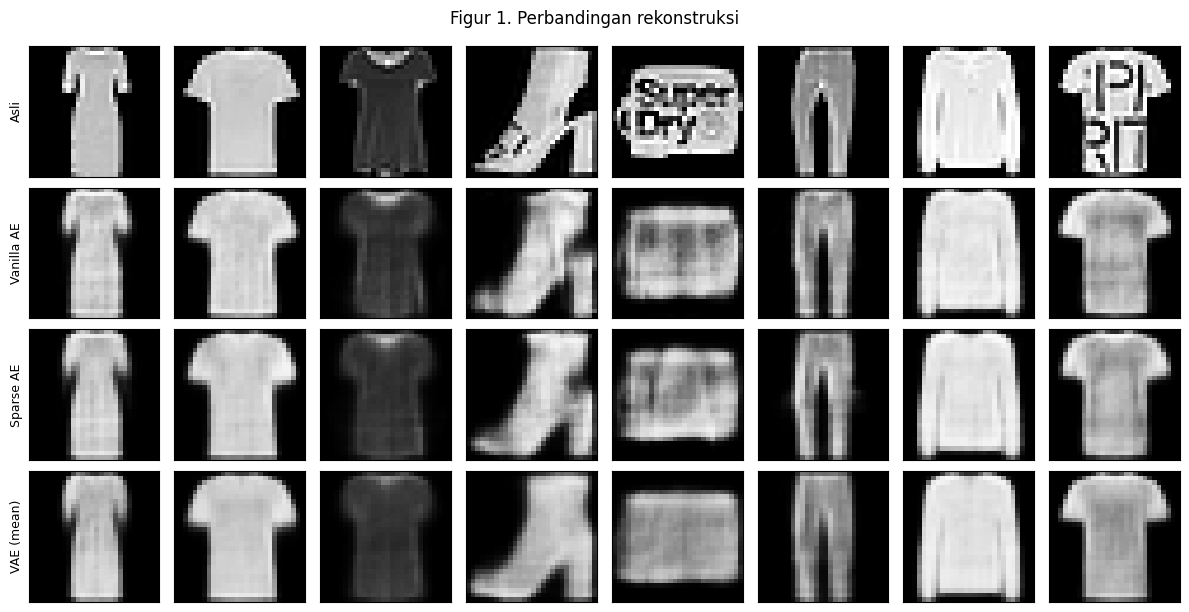

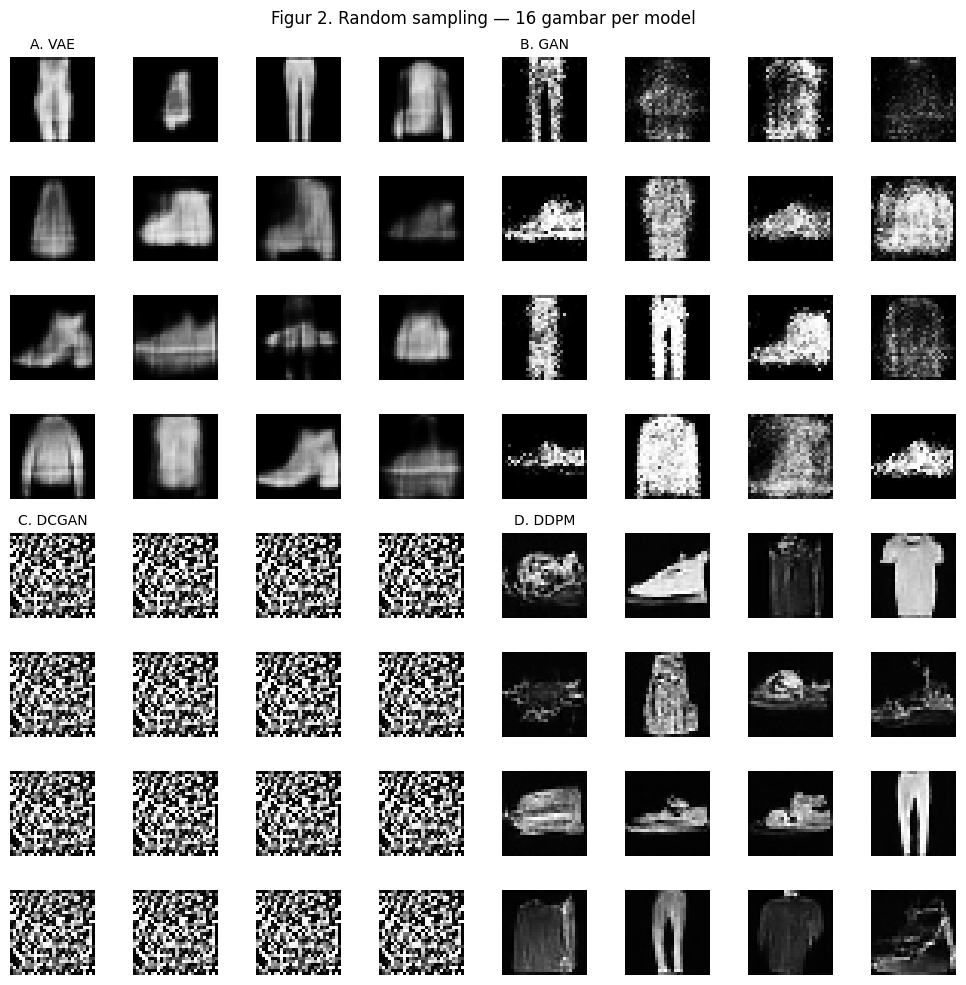

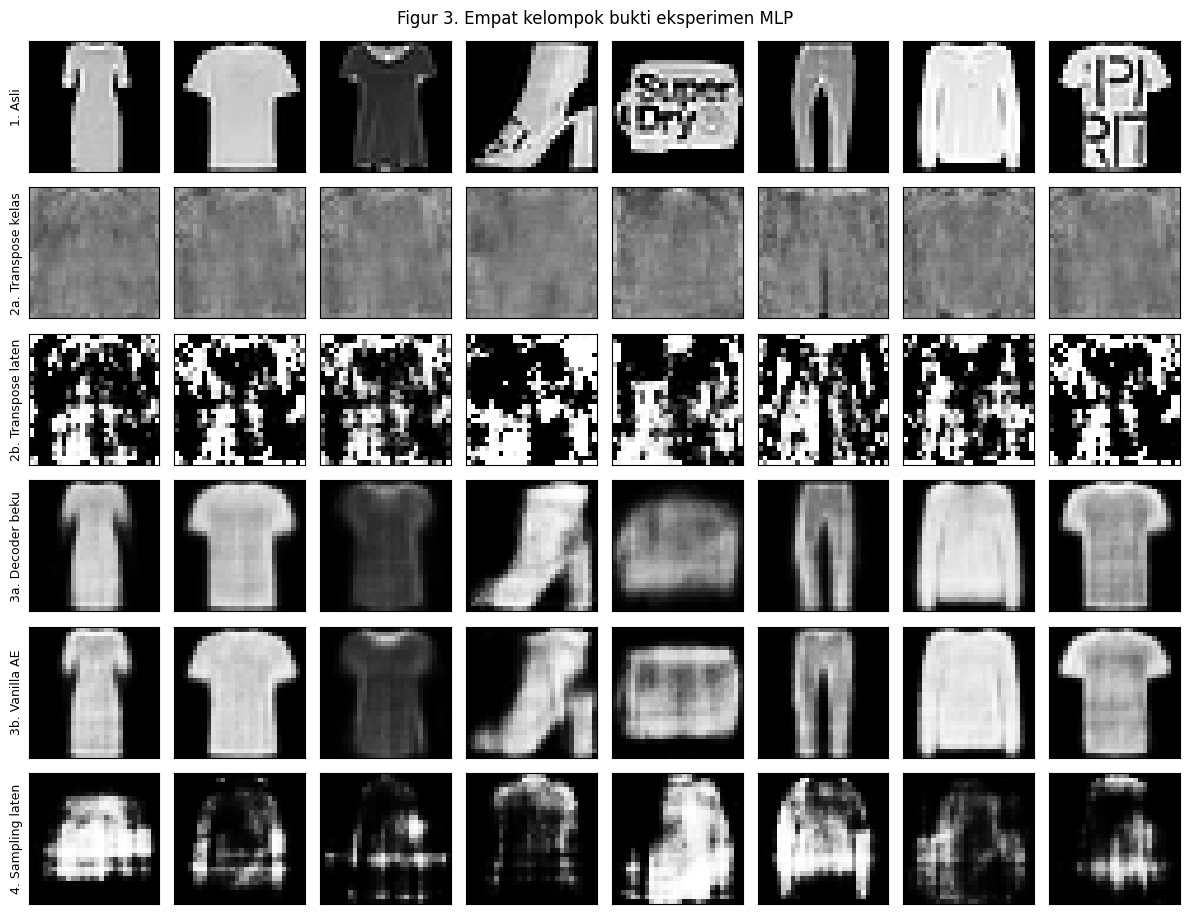

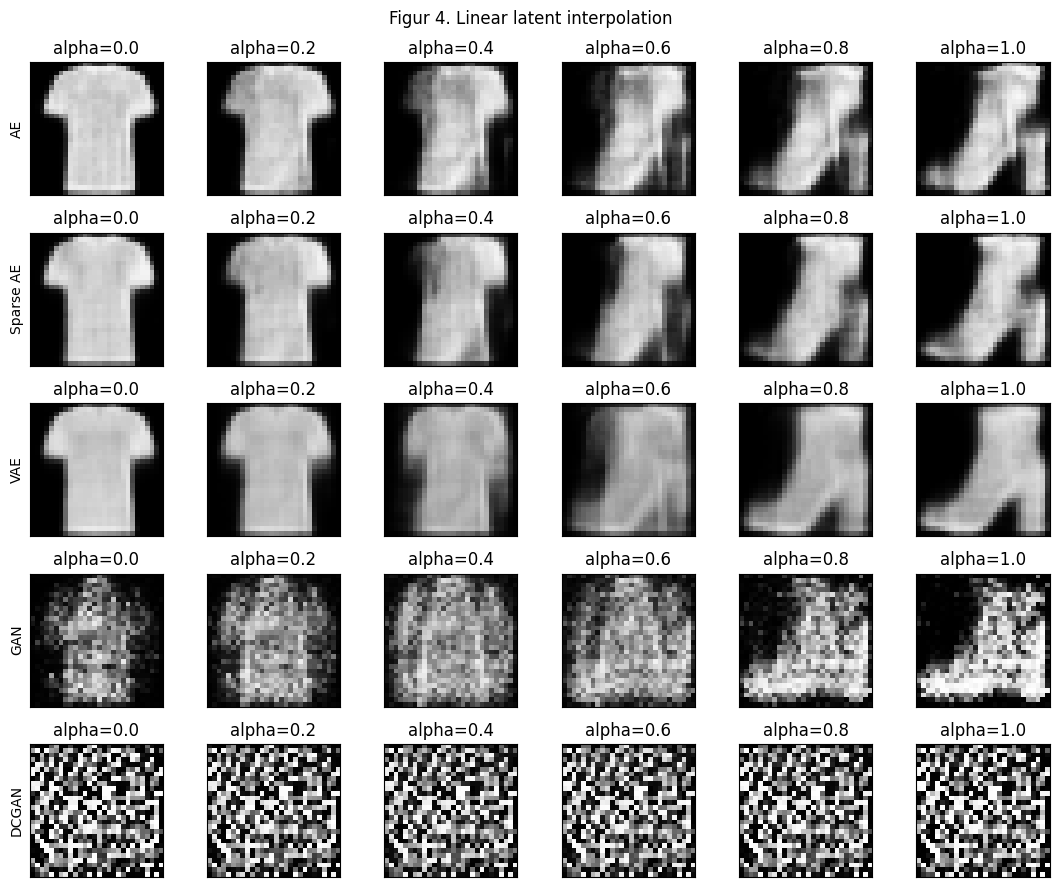

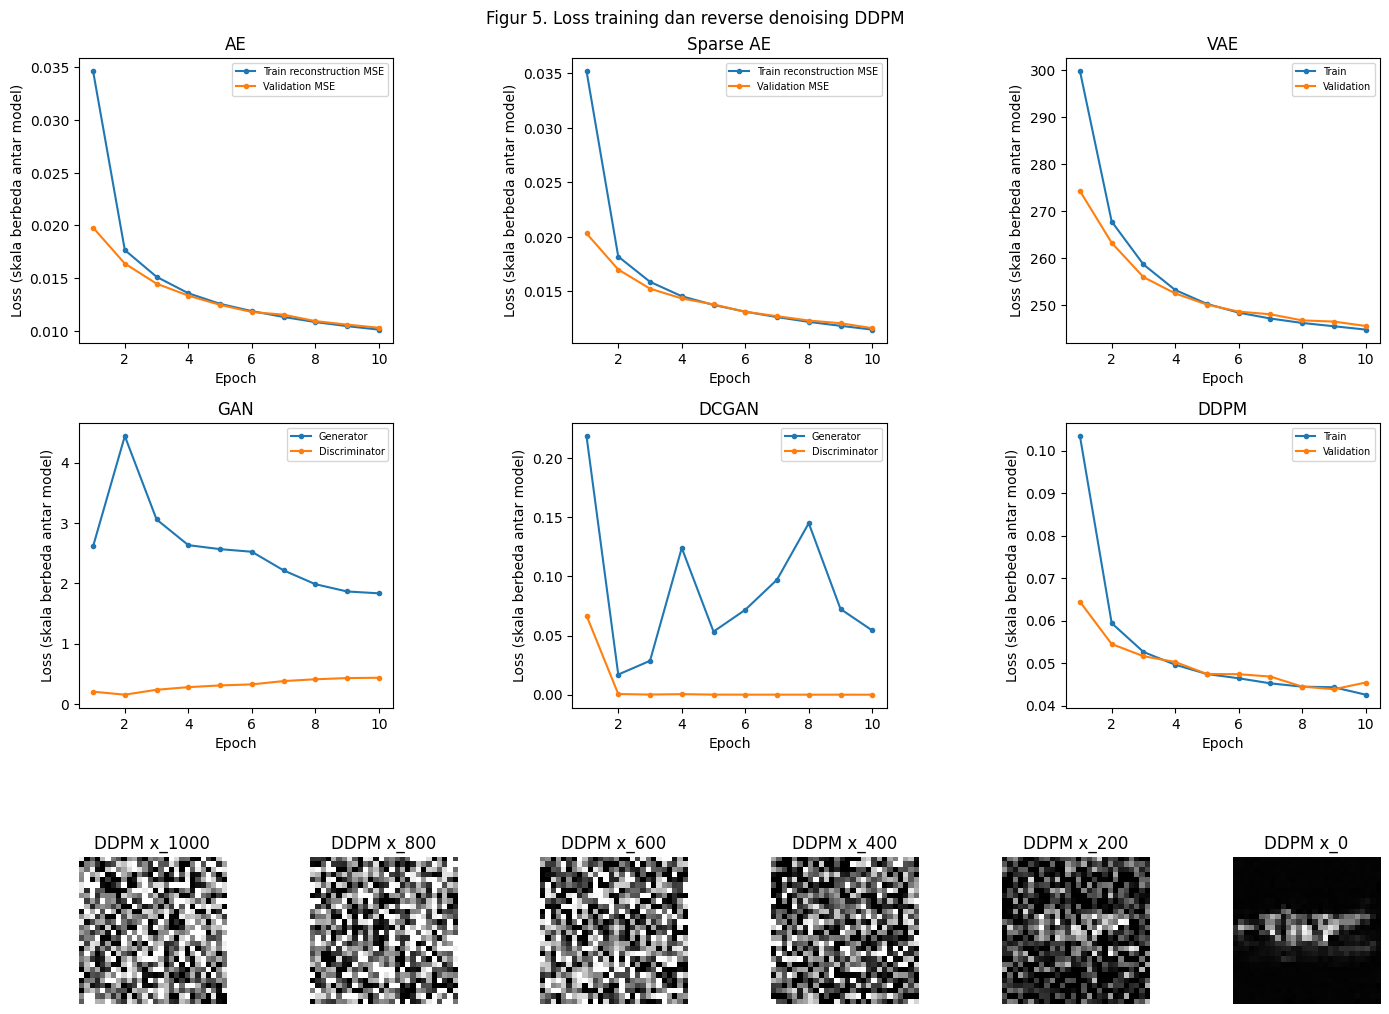

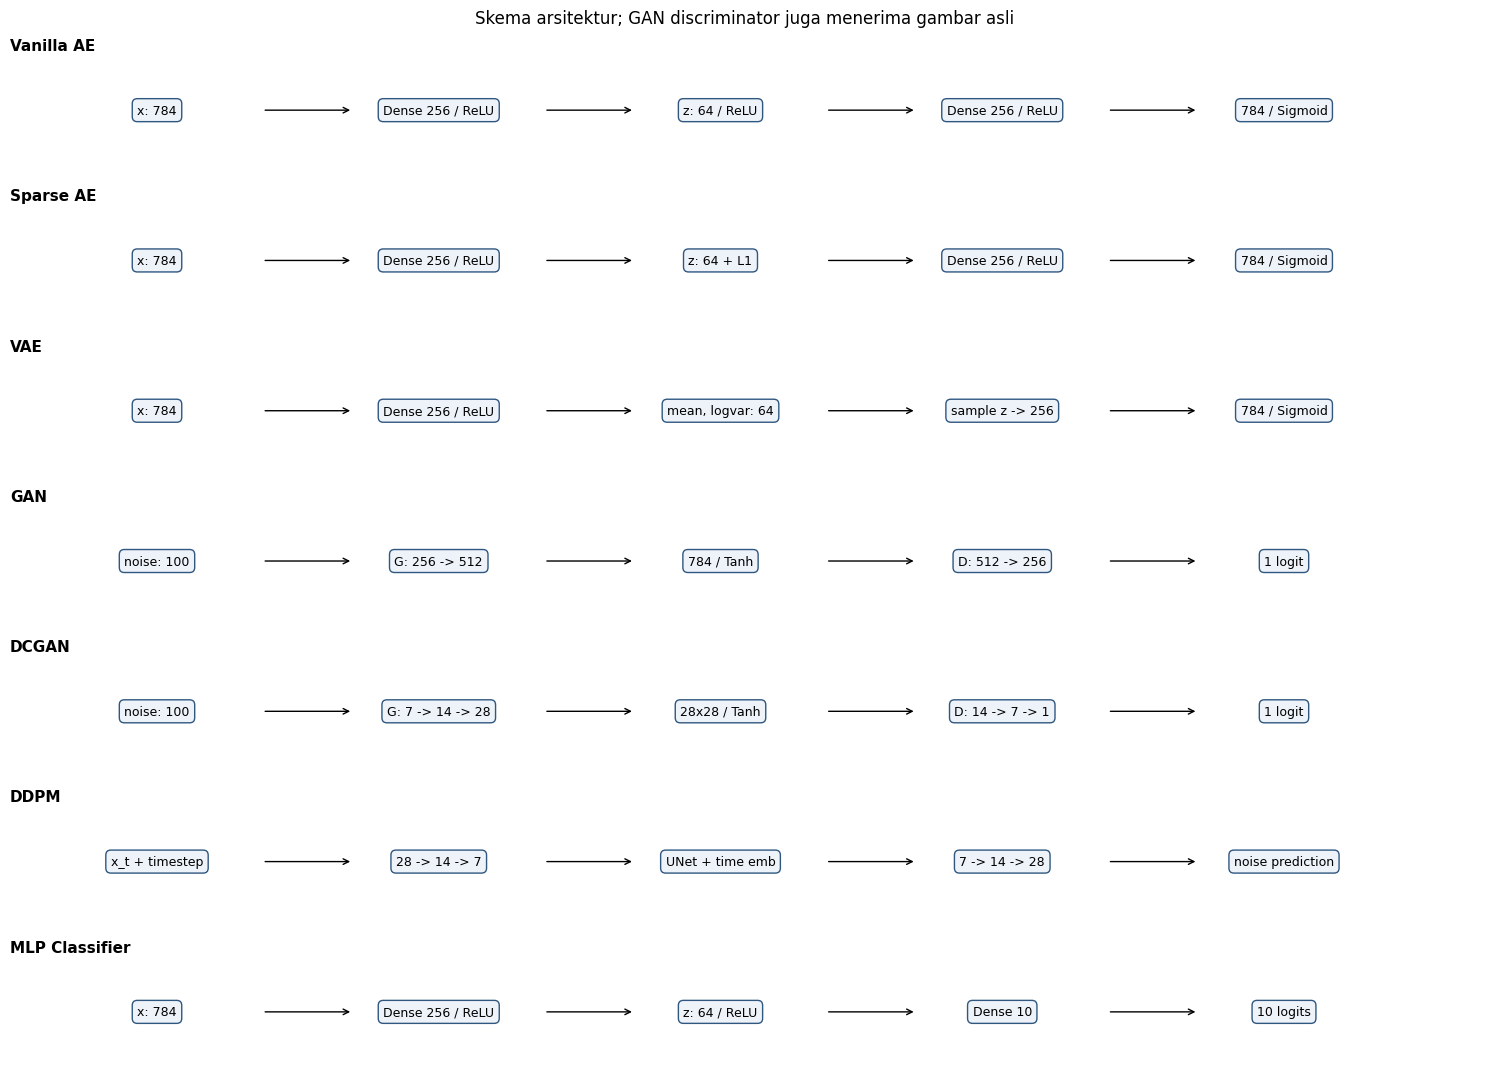

In [ ]:
interpolation_notes = make_figures(
    models, histories, schedule, test_loader, mean_z, std_z, device
)
architecture_diagrams()

In [ ]:
torch.save({
    "metrics": rows,
    "classifier_results": classifier_results,
    "interpolation_notes": interpolation_notes,
    "classifier_latent_mean": mean_z.cpu(),
    "classifier_latent_std": std_z.cpu(),
    "histories": histories
}, "evaluation_results.pt")

In [ ]:
print(classifier_results["frozen_decoder"])
print(classifier_results["latent_transpose"])

{'MSE': 0.018759557144982474, 'PSNR': 17.93824192592076, 'SSIM': 0.6321493597504065}
{'MSE': 0.26069713265555244, 'PSNR': 5.893766911097935, 'SSIM': 0.10863303860642973}
